# Open the frozen shell: establish the geometry first

What changes when we remove a cap from the [sampled closed shell](../closed_shell/index.md)?
This **66-ball subset** retains every remaining coordinate, radius and parent
atom identity. Nothing is regenerated. The parent has 72 balls, all of radius
**1.7 Å**, around a nominal 6 Å sphere. There is no periodic boundary.

This notebook establishes independent probe-center access, enclosure and
exclusion controls without importing TopoMT or DFND. The separate
[DFND notebook](dfnd.ipynb) reads the committed reference in a fresh kernel.
Run from this directory: neither notebook writes artifacts, launches an
external engine or contacts a server.

In [1]:
import hashlib
import html
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyunitwizard as puw
from IPython.display import Markdown, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from pyunitwizard import QuantityRecord
from scipy.spatial import ConvexHull

DATA = Path('artifacts/shell_with_opening_v1')
protocol_bytes = (DATA/'protocol.json').read_bytes()
protocol = json.loads(protocol_bytes)
input_bytes = Path(protocol['source_file']).read_bytes()
fixture = json.loads(input_bytes)
parent_dir = Path(protocol['parent_directory'])
parent_bytes = (parent_dir/protocol['parent_input_file']).read_bytes()
parent = json.loads(parent_bytes)
parent_reference = json.loads((parent_dir/protocol['parent_reference_file']).read_bytes())
assert hashlib.sha256(input_bytes).hexdigest() == protocol['input_sha256']
assert hashlib.sha256(parent_bytes).hexdigest() == fixture['parent_input']['sha256']
assert hashlib.sha256(Path(protocol['pdb_file']).read_bytes()).hexdigest() == protocol['pdb_sha256']
for relative, digest in protocol['parent_preserved_files'].items():
    assert hashlib.sha256((parent_dir/relative).read_bytes()).hexdigest() == digest

def values(record, field, unit):
    quantity = QuantityRecord.from_dict(record).to_quantity(field=field, unit=unit)
    return np.asarray(puw.get_value(quantity, to_unit=unit))

def qrecord(data, unit, field):
    return QuantityRecord.from_quantity(puw.quantity(data, unit), field=field).to_dict()

def table(headers, rows):
    lines = ['| '+' | '.join(headers)+' |', '| '+' | '.join(['---']*len(headers))+' |']
    lines += ['| '+' | '.join(str(value) for value in row)+' |' for row in rows]
    display(Markdown(chr(10).join(lines)))

coords = values(fixture['coordinates'], 'coordinates', 'angstroms')
radii = values(fixture['atom_radii'], 'atom_radii', 'angstroms')
parent_coords = values(parent['coordinates'], 'coordinates', 'angstroms')
parent_radii = values(parent['atom_radii'], 'atom_radii', 'angstroms')
origin = values(protocol['origin'], 'origin', 'angstroms')
derivation = fixture['derivation']
direction = values(derivation['axis'], 'axis', 'dimensionless')
half_angle = float(values(derivation['half_angle'], 'half_angle', 'radians'))
parent_ids = np.asarray(derivation['parent_atom_indices'], dtype=int)
removed = np.asarray(derivation['removed_parent_atom_indices'], dtype=int)
atol = float(values(protocol['tolerances']['length_absolute'], 'length_absolute', 'angstroms'))
delta_parent = parent_coords-origin
polar_cosine = delta_parent@direction/np.linalg.norm(delta_parent, axis=1)
np.testing.assert_allclose(np.linalg.norm(direction), 1, rtol=0, atol=1e-14)
assert np.flatnonzero(polar_cosine > np.cos(half_angle)).tolist() == removed.tolist()
np.testing.assert_array_equal(coords, parent_coords[parent_ids])
np.testing.assert_array_equal(radii, parent_radii[parent_ids])
assert coords.shape == (66,3) and removed.tolist() == list(range(6))
table(['Construction', 'Frozen value'], [
    ['Parent / child balls', '72 / 66'], ['Deleted parent IDs (zero-based)', removed.tolist()],
    ['Retained parent IDs', '6 through 71, original order'],
    ['Cap rule', 'Remove polar angle < 35 degrees from +Y; retain the boundary'],
    ['Primary probes', '1.4 / 3.0 / 5.0 Å'], ['Atomic radii', '1.7 Å, explicit JSON values']])

| Construction | Frozen value |
| --- | --- |
| Parent / child balls | 72 / 66 |
| Deleted parent IDs (zero-based) | [0, 1, 2, 3, 4, 5] |
| Retained parent IDs | 6 through 71, original order |
| Cap rule | Remove polar angle < 35 degrees from +Y; retain the boundary |
| Primary probes | 1.4 / 3.0 / 5.0 Å |
| Atomic radii | 1.7 Å, explicit JSON values |

## What the deletion isolates

The strict polar-cap rule deletes six atoms. PDB serial and residue numbers
remain 7–72; the gaps preserve parent identity. The exchange PDB rounds
coordinates and cannot carry explicit radii. These references use the full
precision quantity-aware JSON, without inferring molecular chemistry.

**A certified path at 1.4 Å.** For a unit direction d, atom a_i and origin o,
the point on the forward ray closest to that atom is at
t_i = max(0, (a_i−o)·d). Its clearance is
||a_i−o−t_i d||−r_i. The minimum over all retained atoms bounds the clearance
of the entire continuous ray, including beyond the hull.

A second, conservative construction bound is
min_i ||a_i−o|| sin(35°) − max_i r_i. Retained atoms in the forward hemisphere
have polar angle at least 35°; rear atoms have their closest ray point at
the origin. A positive margin above 1.4 Å independently certifies access.

**Enclosure at 3 Å.** For every triangle of the child convex hull, compute
its circumradius R_f. At any point p in that triangle, barycentric weights
satisfy

$$\sum_i \lambda_i ||p-a_i||^2 = R_f^2-||p-c_f||^2 \leq R_f^2.$$

Some vertex therefore lies within R_f. If min(r_i)+probe exceeds every R_f,
expanded atomic balls cover the whole hull boundary. A free origin strictly
inside that boundary belongs to a bounded free probe-center component.

**Exclusion at 5 Å.** If all centers lie within radius R of o, any point p
in their convex hull satisfies
sum_i λ_i ||p−a_i||² = sum_i λ_i ||a_i−o||²−||p−o||² ≤ R².
Some atom lies within R. If min(r_i)+probe > R, no center fits anywhere in
the finite hull. These are sufficient bounds, not exact transition radii.

In [2]:
def wall_geometry(points, atom_radii):
    hull = ConvexHull(points)
    triangles = points[hull.simplices]
    a = np.linalg.norm(triangles[:,0]-triangles[:,1], axis=1)
    b = np.linalg.norm(triangles[:,1]-triangles[:,2], axis=1)
    c = np.linalg.norm(triangles[:,2]-triangles[:,0], axis=1)
    area = np.linalg.norm(np.cross(triangles[:,1]-triangles[:,0], triangles[:,2]-triangles[:,0]), axis=1)/2
    face_cover = a*b*c/(4*area)
    delta = points-origin
    projected = np.maximum(delta@direction, 0)
    clearance = np.linalg.norm(delta-projected[:,None]*direction, axis=1)-atom_radii
    origin_clearance = float(np.min(np.linalg.norm(delta, axis=1)-atom_radii))
    enclosing_radius = float(np.max(np.linalg.norm(delta, axis=1)))
    assert np.all(hull.equations[:,:3]@origin+hull.equations[:,3] < -atol)
    return hull, face_cover, clearance, origin_clearance, enclosing_radius

hull, face_cover, per_atom_clearance, center_clearance, enclosing_radius = wall_geometry(coords, radii)
parent_hull, parent_cover, parent_ray, parent_center_clearance, _ = wall_geometry(parent_coords, parent_radii)
cap_bound = float(np.min(np.linalg.norm(delta_parent, axis=1))*np.sin(half_angle)-radii.max())
ray_clearance = float(per_atom_clearance.min())
terminal_distance = float(np.max(np.linalg.norm(coords-origin, axis=1)+radii)+5.1)
terminal = origin+terminal_distance*direction
assert np.any(hull.equations[:,:3]@terminal+hull.equations[:,3] > atol)
assert ray_clearance > cap_bound > 1.4+atol
assert parent_radii.min()+1.4-parent_cover.max() > atol
assert parent_center_clearance > 1.4+atol
assert radii.min()+3-face_cover.max() > atol and center_clearance > 3+atol
assert radii.min()+5-enclosing_radius > atol
blockers = np.flatnonzero(parent_ray < 1.4+atol).tolist()
assert blockers and set(blockers) <= set(removed)
np.testing.assert_allclose(parent_cover.max(), values(parent_reference['certificates']['maximum_face_cover_radius'],
    'maximum_face_cover_radius', 'angstroms'), rtol=0, atol=1e-12)
parent_faces = {tuple(sorted(map(int, face))) for face in parent_hull.simplices}
child_faces = {tuple(sorted(map(int, parent_ids[face]))) for face in hull.simplices}
unchanged_faces = sorted(child_faces & parent_faces)
new_faces = sorted(child_faces-parent_faces)
assert new_faces and unchanged_faces
experiments = []
for declared in protocol['experiments']:
    probe = float(values(declared['probe_radius'], 'probe_radius', 'angstroms'))
    experiments.append({**declared, 'origin_free':bool(center_clearance-probe > atol),
        'ray_margin':qrecord(ray_clearance-probe, 'angstroms', 'ray_margin'),
        'wall_coverage_margin':qrecord(float(radii.min()+probe-face_cover.max()), 'angstroms', 'wall_coverage_margin'),
        'origin_margin':qrecord(center_clearance-probe, 'angstroms', 'origin_margin'),
        'full_hull_coverage_margin':qrecord(float(radii.min()+probe-enclosing_radius), 'angstroms', 'full_hull_coverage_margin')})
table(['Independent evidence', 'Value (Å)'], [
    ['Child +Y ray minimum clearance', f'{ray_clearance:.9f}'],
    ['Conservative cap clearance bound', f'{cap_bound:.9f}'],
    ['Parent wall-coverage margin at 1.4 Å', f'{parent_radii.min()+1.4-parent_cover.max():.9f}'],
    ['Child wall-coverage margin at 3 Å', f'{radii.min()+3-face_cover.max():.9f}'],
    ['Child origin clearance', f'{center_clearance:.9f}'],
    ['Child full-hull coverage margin at 5 Å', f'{radii.min()+5-enclosing_radius:.9f}']])

| Independent evidence | Value (Å) |
| --- | --- |
| Child +Y ray minimum clearance | 1.819726044 |
| Conservative cap clearance bound | 1.665782356 |
| Parent wall-coverage margin at 1.4 Å | 1.070469277 |
| Child wall-coverage margin at 3 Å | 0.989869356 |
| Child origin clearance | 4.168062464 |
| Child full-hull coverage margin at 5 Å | 0.556631217 |

The same 1.4 Å probe is enclosed by the parent wall and has a continuous
escape witness after deletion. At 3 Å, the opening is blocked even though
the origin remains free; at 5 Å, the entire finite hull excludes centers.
The construction has one deleted cap, but this proof does not count physical
mouths or all other free regions.

The parent hull triangles that survive the deletion retain their three
original vertex balls and remain covered at 1.4 Å. Consequently, any genuine
free exterior contact on the child hull must occur on a **newly exposed
child hull triangle**. Compare triangles by sorted parent atom IDs, not by
carrier-cell IDs: deletion retriangulates the finite carrier.

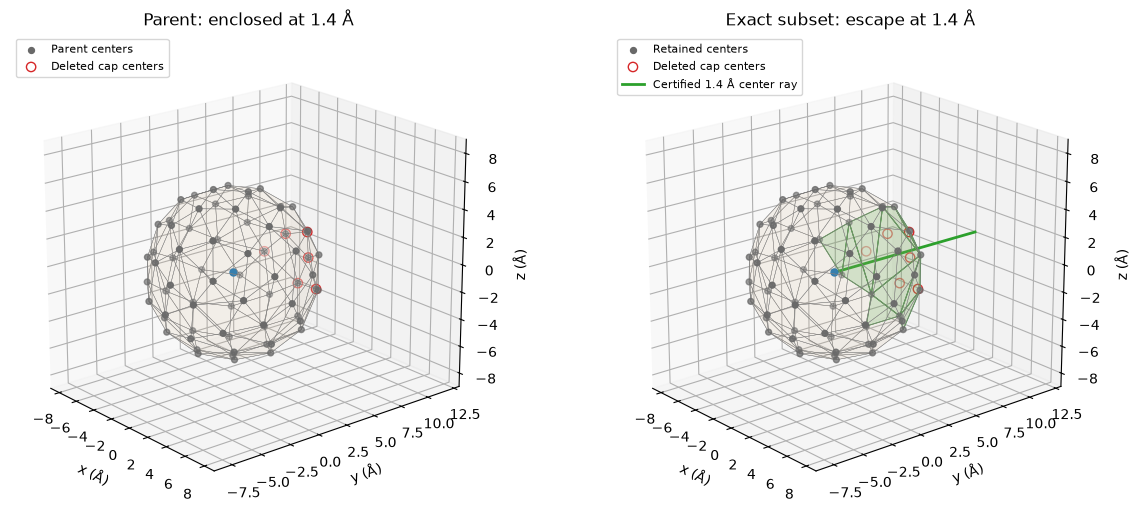

In [3]:
fig = plt.figure(figsize=(12,5.1), constrained_layout=True)
for panel, (points, mesh, title) in enumerate([
    (parent_coords, parent_hull, 'Parent: enclosed at 1.4 Å'),
    (coords, hull, 'Exact subset: escape at 1.4 Å')], start=1):
    ax = fig.add_subplot(1,2,panel, projection='3d')
    ax.add_collection3d(Poly3DCollection(points[mesh.simplices], facecolor='tan', edgecolor='grey', alpha=.07, linewidth=.3))
    ax.scatter(*points.T, s=18, color='dimgray', label='Retained centers' if panel==2 else 'Parent centers')
    ax.scatter(*parent_coords[removed].T, s=45, facecolors='none', edgecolors='tab:red', label='Deleted cap centers')
    if panel==2:
        local = {int(parent_id):index for index,parent_id in enumerate(parent_ids)}
        patch = coords[[[local[atom] for atom in face] for face in new_faces]]
        ax.add_collection3d(Poly3DCollection(patch, facecolor='tab:green', edgecolor='tab:green', alpha=.18, linewidth=.7))
        ax.plot(*np.stack([origin,terminal]).T, color='tab:green', lw=2, label='Certified 1.4 Å center ray')
    ax.scatter(*origin, s=25, color='tab:blue')
    ax.set(xlim=(-9,9), ylim=(-9,13), zlim=(-9,9), xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)', title=title)
    ax.set_box_aspect((18,22,18)); ax.view_init(elev=20, azim=-40); ax.legend(fontsize=8, loc='upper left')
plt.show()

The figures show atomic centers and the finite hull used by the proof;
neither is the atomic-ball union surface. Green triangles are newly exposed
hull faces, rather than a measured physical mouth. The green ray is a
certified continuous center path, not a graph skeleton.

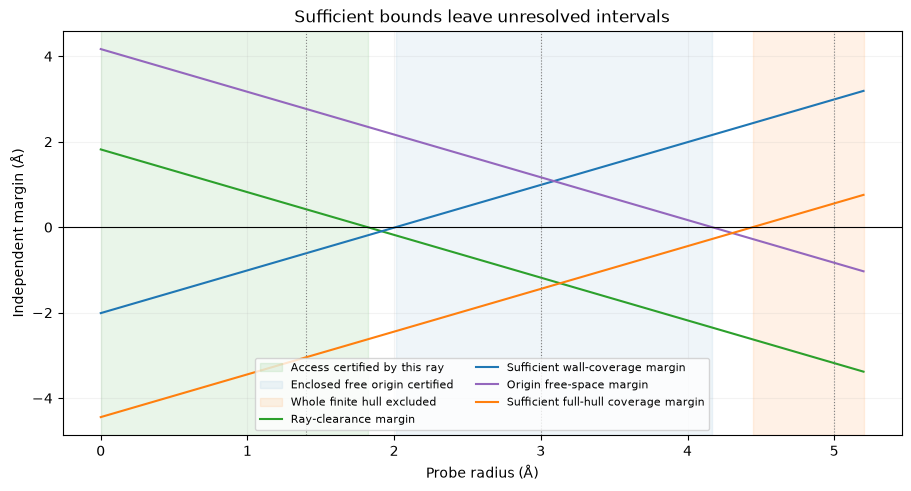

In [4]:
probes = np.linspace(0,5.2,105)
fig,ax = plt.subplots(figsize=(9,4.8), constrained_layout=True)
ax.axvspan(0,ray_clearance, color='tab:green', alpha=.10, label='Access certified by this ray')
ax.axvspan(face_cover.max()-radii.min(), center_clearance, color='tab:blue', alpha=.07, label='Enclosed free origin certified')
ax.axvspan(enclosing_radius-radii.min(),probes.max(), color='tab:orange', alpha=.10, label='Whole finite hull excluded')
ax.plot(probes,ray_clearance-probes, color='tab:green', label='Ray-clearance margin')
ax.plot(probes,radii.min()+probes-face_cover.max(), color='tab:blue', label='Sufficient wall-coverage margin')
ax.plot(probes,center_clearance-probes, color='tab:purple', label='Origin free-space margin')
ax.plot(probes,radii.min()+probes-enclosing_radius, color='tab:orange', label='Sufficient full-hull coverage margin')
ax.axhline(0,color='black', lw=.8)
for probe in (1.4,3.,5.): ax.axvline(probe,color='grey',ls=':',lw=.8)
ax.set(xlabel='Probe radius (Å)', ylabel='Independent margin (Å)', title='Sufficient bounds leave unresolved intervals')
ax.grid(alpha=.15); ax.legend(fontsize=8, ncol=2)
plt.show()

These bounds leave intervals without a disposition. A negative ray margin
does not exclude a curved escape path; a negative wall bound does not prove
a leak. Their endpoints are sufficient certificates, not exact physical
transition values. Nor does access on this case validate all DFND paths.

## Frozen handoff to native observation

The report carries explicit quantities, input/protocol hashes, parent atom
correspondence and hull-face keys. It is frozen before running the separate
native notebook. Ordinary reruns display recomputed evidence without writing
the committed reference. Volume accuracy (#75), the full independent panel
(#76), third-party comparisons and proteins remain separate work.

In [5]:
reference = {
    'schema':'topomt.benchlab.shell-opening-reference/1', 'case_id':'shell_with_opening', 'case_version':1,
    'input_sha256':hashlib.sha256(input_bytes).hexdigest(), 'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest(),
    'parent_input_sha256':hashlib.sha256(parent_bytes).hexdigest(),
    'reference_checks':'passed', 'atom_count':len(coords), 'parent_atom_indices':parent_ids.tolist(),
    'removed_parent_atom_indices':removed.tolist(), 'hull_face_count':len(hull.simplices),
    'certificates':{
        'maximum_face_cover_radius':qrecord(float(face_cover.max()),'angstroms','maximum_face_cover_radius'),
        'face_cover_radii':qrecord(face_cover,'angstroms','face_cover_radii'),
        'center_clearance':qrecord(center_clearance,'angstroms','center_clearance'),
        'enclosing_radius':qrecord(enclosing_radius,'angstroms','enclosing_radius')},
    'escape_witness':{'origin':protocol['origin'], 'axis':derivation['axis'],
        'per_atom_clearance':qrecord(per_atom_clearance,'angstroms','per_atom_clearance'),
        'minimum_clearance':qrecord(ray_clearance,'angstroms','minimum_clearance'),
        'cap_clearance_lower_bound':qrecord(cap_bound,'angstroms','cap_clearance_lower_bound'),
        'terminal_point':qrecord(terminal,'angstroms','terminal_point')},
    'parent_control':{**protocol['parent_control'],
        'maximum_face_cover_radius':qrecord(float(parent_cover.max()),'angstroms','maximum_face_cover_radius'),
        'wall_coverage_margin':qrecord(float(parent_radii.min()+1.4-parent_cover.max()),'angstroms','wall_coverage_margin'),
        'axis_ray_blocking_parent_ids':blockers},
    'contact_reference':{'new_child_hull_faces_parent_ids':[list(face) for face in new_faces],
        'unchanged_child_hull_faces_parent_ids':[list(face) for face in unchanged_faces],
        'proof':protocol['contact_reference']},
    'experiments':experiments, 'tolerances':protocol['tolerances'], 'limits':protocol['scope_limits']}
report_text = json.dumps(reference, indent=2, allow_nan=False)
display({'text/plain':report_text, 'text/html':'<details><summary>Complete independent reference</summary><pre>'
    +html.escape(report_text)+'</pre></details>'}, raw=True)

{
  "schema": "topomt.benchlab.shell-opening-reference/1",
  "case_id": "shell_with_opening",
  "case_version": 1,
  "input_sha256": "3a62da60d3812707f254d7a393f61e9f2f241fa103a9a546afa2d12d1d2b4b77",
  "protocol_sha256": "8bedb65df869ba10b5b57b65925fe5660fb0bd77c6486074d5dba176a991e74e",
  "parent_input_sha256": "ef19995751b2df58c8b1556011f74fa4774e924b9cd499138b8741988b650157",
  "reference_checks": "passed",
  "atom_count": 66,
  "parent_atom_indices": [
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71
  ],
  "removed_parent_atom_indices": [
    0,
    1,
    2,
    3,
    4,
    5
  ],
  "hull_face_count": 128,
  "certificates": {
    "maximum_face_cover_radius": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "maximum_face_cover_radius",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 3.710130644473083,
      "block_digests": [
        "blake2b-128:60c65dc190aad0f03ec4996b312edd40"
      ],
      "digest": "blake2b-128:e49e90d08e9fd9f0f1555688de98060d"
    },
    "face_cover_radii": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "face_cover_radii",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [
          128
        ],
        "blocks": [
          128
        ]
      },
      "values": [
        1.7194455403381104,
        1.6966372581289133,
        1.5662367383165068,
        1.6331037801626,
        1.6517450739626611,
        1.669174593628245,
        1.9336527333789018,
        1.6970210286302116,
        1.7777336547845395,
        1.4170781291628483,
        1.5043022281268303,
        1.7547984105339274,
        1.8021751182871408,
        1.731830142548485,
        1.6738648039312427,
        1.7990456785039928,
        1.5943755728599378,
        1.6436715717011654,
        1.7030580476431825,
        1.536812429947679,
        1.5525897574332617,
        2.0295307231266912,
        1.9014533493229964,
        1.7483220614517072,
        1.7045695630311781,
        1.6219206682809917,
        1.6754109531346026,
        1.761363167797463,
        1.7627726705301336,
        1.798679673292594,
        1.7047905154980438,
        1.7130353431171257,
        1.5772396635213084,
        1.6765064228784523,
        1.6960549521537762,
        1.6251777315095395,
        1.6027933901201221,
        1.5120266571330176,
        1.7242133174588328,
        1.7135006658756524,
        1.6772092061048354,
        1.6845107219938058,
        1.9431718800052262,
        1.6435309598606878,
        1.7549441832745345,
        1.608973221350372,
        1.8816762575023227,
        1.7596207869172062,
        1.7583581454417463,
        1.7214973090156866,
        1.6753656511774437,
        1.8942424643924232,
        1.6191188996764607,
        1.761361776254215,
        1.8689849254085429,
        1.5836823794713482,
        1.6474457160922105,
        1.6144242307701804,
        1.5971928545938665,
        1.511937462260154,
        1.7310440602096202,
        1.6701695768537668,
        1.6689203139555029,
        1.8066861035381205,
        1.6808588296650617,
        1.5954382495286485,
        1.5692380629223317,
        1.8